# NFL Kaggle dataset
## Parte 2

### Importar bibliotecas

In [1]:
import os
import numpy as np
import pandas as pd

### Carregar dataset

In [2]:
csv_path = r"C:\Users\52068085801\.cache\kagglehub\datasets\maxhorowitz\nflplaybyplay2009to2016\versions\6"

df = pd.read_parquet(csv_path + r"\NFL Play by Play 2009-2017 (v4) PROCESSED.parquet")
# O r antes da string indica que ela é uma raw string (string literal bruta). 
# Serve para o Python não interpretar caracteres de escape, especialmente a barra invertida \.

### 1) Visão Geral Estutural
Objetivo, entender o formato do dataset.

In [3]:
df.head()

,Date,GameID,Drive,qtr,down,time,TimeUnder,TimeSecs,PlayTimeDiff,SideofField,...,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season
0,2009-09-10,2009091000,1,1,NaN,0 days 00:15:00,15,3600.0,0.0,TEN,...,NaN,0.485675,0.514325,0.546433,0.453567,0.485675,0.060758,NaN,NaN,2009
1,2009-09-10,2009091000,1,1,1.0,0 days 00:14:53,15,3593.0,7.0,PIT,...,1.146076,0.546433,0.453567,0.551088,0.448912,0.546433,0.004655,-0.032244,0.036899,2009
2,2009-09-10,2009091000,1,1,2.0,0 days 00:14:16,15,3556.0,37.0,PIT,...,NaN,0.551088,0.448912,0.510793,0.489207,0.551088,-0.040295,NaN,NaN,2009
3,2009-09-10,2009091000,1,1,3.0,0 days 00:13:35,14,3515.0,41.0,PIT,...,-5.031425,0.510793,0.489207,0.461217,0.538783,0.510793,-0.049576,0.106663,-0.156239,2009
4,2009-09-10,2009091000,1,1,4.0,0 days 00:13:27,14,3507.0,8.0,PIT,...,NaN,0.461217,0.538783,0.558929,0.441071,0.461217,0.097712,NaN,NaN,2009


In [4]:
df.shape

(407688, 102)

In [5]:
df.info(verbose=True) 

<class 'pandas.DataFrame'>
RangeIndex: 407688 entries, 0 to 407687
Data columns (total 102 columns):
 #    Column                       Dtype          
---   ------                       -----          
 0    Date                         datetime64[ns] 
 1    GameID                       int64          
 2    Drive                        int64          
 3    qtr                          int64          
 4    down                         float64        
 5    time                         timedelta64[us]
 6    TimeUnder                    int64          
 7    TimeSecs                     float64        
 8    PlayTimeDiff                 float64        
 9    SideofField                  category       
 10   yrdln                        float64        
 11   yrdline100                   float64        
 12   ydstogo                      int64          
 13   ydsnet                       int64          
 14   GoalToGo                     float64        
 15   FirstDown                 

### 2) Análise de valores ausentes
Objetivo, detectar problemas de completude.

In [6]:
pd.set_option('display.max_rows', None)  # Mostra todas as linhas
missing = df.isna().sum().sort_values(ascending=False)
missing

DefTwoPoint                    407664
BlockingPlayer                 407571
TwoPointConv                   407083
ChalReplayResult               404286
RecFumbPlayer                  403315
RecFumbTeam                    403315
Interceptor                    403168
FieldGoalDistance              398740
FieldGoalResult                398629
ExPointResult                  397578
PenaltyType                    391261
Timeout_Team                   390885
ReturnResult                   389450
PuntResult                     385317
Returner                       382384
PenalizedPlayer                379403
PenalizedTeam                  378189
Tackler2                       357953
RunGap                         320260
RunLocation                    288178
Rusher                         287124
Rusher_ID                      283654
Receiver_ID                    250328
yacWPA                         248762
airWPA                         248501
yacEPA                         248498
airEPA      

In [7]:
missing_percent = df.isna().mean() * 100
missing_percent.sort_values(ascending=False)

DefTwoPoint                    99.994113
BlockingPlayer                 99.971302
TwoPointConv                   99.851602
ChalReplayResult               99.165538
RecFumbPlayer                  98.927366
RecFumbTeam                    98.927366
Interceptor                    98.891309
FieldGoalDistance              97.805184
FieldGoalResult                97.777958
ExPointResult                  97.520162
PenaltyType                    95.970693
Timeout_Team                   95.878466
ReturnResult                   95.526481
PuntResult                     94.512716
Returner                       93.793293
PenalizedPlayer                93.062097
PenalizedTeam                  92.764320
Tackler2                       87.800720
RunGap                         78.555170
RunLocation                    70.685917
Rusher                         70.427386
Rusher_ID                      69.576245
Receiver_ID                    61.401856
yacWPA                         61.017739
airWPA          

#### Interpretação:

| Percentual de missing | Interpretação | Ação recomendada      |
| --------------------- | ------------- | --------------------- |
| 0%                    | perfeito      | manter                |
| 0 a 5%                | muito baixo   | imputação simples     |
| 5 a 10%               | baixo         | imputação segura      |
| 10 a 20%              | moderado      | imputação com cautela |
| 20 a 30%              | alto          | avaliar importância   |
| 30 a 50%              | muito alto    | geralmente remover    |
| > 50%                 | crítico       | remover quase sempre  |


#### Identificar colunas com mais de 50% de valores ausentes

In [8]:
missing_50 = missing_percent[missing_percent >= 50].index
missing_50

Index(['ExPointResult', 'TwoPointConv', 'DefTwoPoint', 'PuntResult', 'Passer',
       'Passer_ID', 'PassOutcome', 'PassLength', 'PassLocation', 'Interceptor',
       'Rusher', 'Rusher_ID', 'RunLocation', 'RunGap', 'Receiver',
       'Receiver_ID', 'ReturnResult', 'Returner', 'BlockingPlayer', 'Tackler2',
       'FieldGoalResult', 'FieldGoalDistance', 'RecFumbTeam', 'RecFumbPlayer',
       'ChalReplayResult', 'PenalizedTeam', 'PenaltyType', 'PenalizedPlayer',
       'Timeout_Team', 'airEPA', 'yacEPA', 'airWPA', 'yacWPA'],
      dtype='str')

#### Identificar colunas entre 30% e 50% de valores ausentes

In [9]:
# Identificar colunas com mais de 50% de missing
missing_30_50 = missing_percent[missing_percent.between(30, 50, inclusive='right')].index
missing_30_50

Index(['Tackler1'], dtype='str')

#### Identificar colunas entre 20% e 30% de valores ausentes

In [10]:
missing_20_30 = missing_percent[missing_percent.between(20, 30, inclusive='right')].index
missing_20_30
#print("Total entre 20% e 30%:", colunas_avaliar.shape[0], "colunas")

Index([], dtype='str')

#### Identificar colunas entre 10% e 20% de valores ausentes

In [11]:
missing_10_20 = missing_percent[missing_percent.between(10, 20, inclusive='right')].index
missing_10_20

Index(['down'], dtype='str')

#### Identificar colunas entre 5% e 10% de valores ausentes

In [12]:
missing_5_10 = missing_percent[missing_percent.between(5, 10, inclusive='right')].index
missing_5_10

Index(['FirstDown', 'posteam', 'DefensiveTeam', 'PosTeamScore', 'DefTeamScore',
       'ScoreDiff', 'AbsScoreDiff', 'Home_WP_pre', 'Away_WP_pre',
       'Home_WP_post', 'Away_WP_post', 'Win_Prob'],
      dtype='str')

#### Identificar colunas com menos de 5% de valores ausentes

In [13]:
missing_5 = missing_percent[missing_percent.between(0, 5, inclusive='right')].index
missing_5

Index(['time', 'TimeSecs', 'PlayTimeDiff', 'SideofField', 'yrdln',
       'yrdline100', 'GoalToGo', 'desc', 'No_Score_Prob',
       'Opp_Field_Goal_Prob', 'Opp_Safety_Prob', 'Opp_Touchdown_Prob',
       'Field_Goal_Prob', 'Safety_Prob', 'Touchdown_Prob', 'ExpPts', 'EPA',
       'WPA'],
      dtype='str')

# E agora, como avaliar e como tratar os valores ausentes ?

<div>
<img src=attachment:101072ff-9b00-4ae5-a141-4a7880117e27.png style="height:300px; width:auto;"/>
</div>

# Tipos de Missing Data
### Baseado em Little & Rubin, 2019; Van Buuren, 2018; Enders, 2010

| Tipo | Nome completo | Definição formal moderna | Dependência estatística | Impacto na inferência e ML | Pode ser ignorado sem viés? | Estratégias modernas recomendadas | Analogia prática avançada |
|---|---|---|---|---|---|---|---|
| MCAR | Missing Completely At Random | O mecanismo de ausência é independente de qualquer variável do sistema, observada ou não observada | Totalmente independente | Não introduz viés sistemático, apenas reduz poder estatístico | Sim, sob certas condições | Remoção de casos, imputação simples, Maximum Likelihood, Multiple Imputation | Imagine um telescópio automatizado capturando estrelas. Algumas imagens são perdidas porque um pássaro passou na frente aleatoriamente. A perda não depende do brilho, posição ou tipo da estrela. |
| MAR | Missing At Random | O mecanismo de ausência depende apenas de variáveis observadas, podendo ser modelado estatisticamente | Dependente de variáveis observadas, independente do valor ausente condicionalmente | Pode introduzir viés se ignorado, mas é corrigível com modelagem adequada | Não, exceto se modelado corretamente | Multiple Imputation (MICE), EM Algorithm, regressão múltipla, MissForest, métodos bayesianos | Imagine uma pesquisa online enviada durante o horário comercial. Pessoas que trabalham fora respondem menos. A ausência depende da variável "emprego", que é observável, mas não diretamente da opinião da pessoa. |
| MNAR | Missing Not At Random | O mecanismo de ausência depende do próprio valor ausente, mesmo após considerar variáveis observadas | Dependente do valor ausente ou de variáveis latentes | Introduz viés estrutural severo, difícil de corrigir | Não | Modelos de seleção, modelos de mistura, análise de sensibilidade, modelagem bayesiana completa | Imagine um cofre onde as pessoas guardam dinheiro. Apenas quem tem grandes quantias decide não revelar o valor. O próprio valor influencia a ausência. O silêncio é informativo. |

**Referências:**
- **Little, R. J. A., & Rubin, D. B. (2019).** Statistical Analysis with Missing Data. Wiley.
- **Van Buuren, S. (2018).** Flexible Imputation of Missing Data. CRC Press.
- **Enders, C. K. (2010).** Applied Missing Data Analysis. Guilford Press.
- **Josse, J., & Husson, F. (2016).** Handling missing values in exploratory multivariate data analysis.
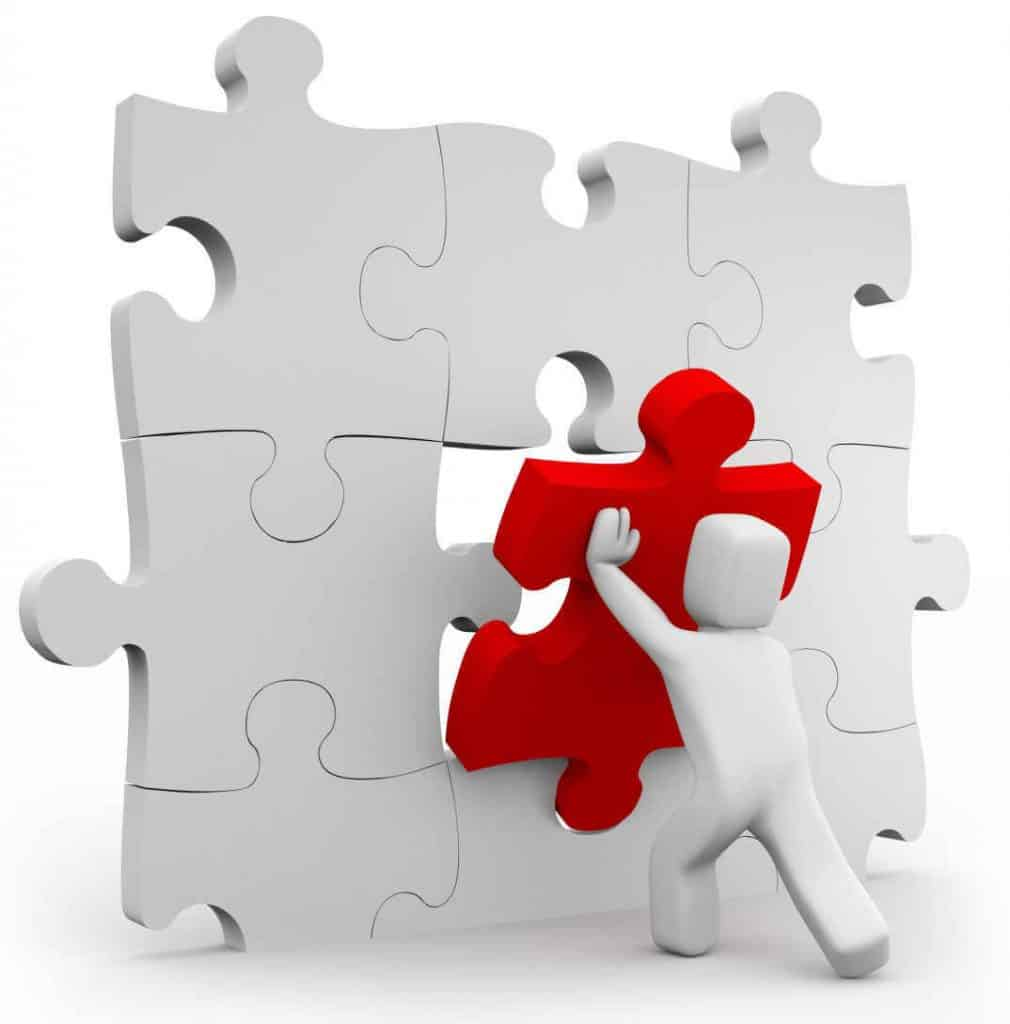

# Consequência prática em Machine Learning

| Tipo | Remover linhas é estatisticamente válido? | Imputação simples é aceitável? | Imputação múltipla é recomendada? | Modelagem explícita do mecanismo é necessária? | Risco em Machine Learning | Analogia conceitual profunda |
|---|---|---|---|---|---|---|
| MCAR | Sim, não introduz viés, apenas reduz tamanho da amostra | Sim | Opcional | Não | Baixo | Como perder aleatoriamente algumas páginas de um livro. A história continua coerente, apenas menos detalhada. |
| MAR | Não recomendado, pode introduzir viés | Não recomendado | Sim, altamente recomendado | Não necessariamente | Moderado | Como tentar estimar a altura média de uma população onde pessoas altas estão mais frequentemente ausentes, mas você ainda tem acesso à idade e gênero para corrigir a estimativa. |
| MNAR | Não, pode distorcer completamente o resultado | Não | Necessário, mas pode não resolver completamente | Sim, obrigatório | Alto | Como medir o nível de medo em uma população onde os mais assustados se recusam a responder. O silêncio contém a informação principal. |

### Tratamento de Dados Ausentes: Imputação e Modelagem do Mecanismo de Missing

O tratamento de dados ausentes (missing data) envolve duas dimensões conceituais distintas:

1. **Métodos de imputação**, que estimam valores ausentes
2. **Modelagem do mecanismo de missing**, que modela o processo que gerou a ausência

Essas duas dimensões resolvem problemas diferentes:

- imputação resolve o problema prático de completar o dataset
- modelagem do mecanismo resolve o problema estatístico de viés

### Métodos de Imputação

Imputação é o processo de substituir valores ausentes por valores estimados.

Existem dois grandes grupos:

- imputação simples
- imputação múltipla

---

### 1. Imputação simples

#### Definição

Imputação simples consiste em substituir cada valor ausente por **um único valor estimado**, sem representar a incerteza dessa estimativa.

Formalmente:

Se:

$
X_i = \text{missing}
$

então substituímos por:

$
X_i = \hat{X}_i
$

onde $\hat{X}_i$ é um valor estimado.

---
#### Métodos de Imputação Simples

| Método | Formulação matemática | Tipo de variável | Descrição | Vantagens | Desvantagens | Quando usar | Exemplo |
|---|---|---|---|---|---|---|---|
| Média | $X_i = \hat{\mu}$, onde $\hat{\mu} = \frac{1}{n} \sum X_{observado}$ | Numérica contínua | Substitui pelo valor médio | Simples, rápido | Reduz variância, distorce distribuição | Missing pequeno, distribuição simétrica | idade missing → 26.7 |
| Mediana | $X_i = \text{mediana}(X)$ | Numérica contínua | Substitui pela mediana | Robusto a outliers | Não preserva variabilidade | Quando há outliers | renda missing → 2500 |
| Moda | $X_i = \text{moda}(X)$ | Categórica | Substitui pela categoria mais frequente | Fácil implementação | Aumenta artificialmente frequência | Categórico com poucos missing | sexo missing → "F" |
| Valor constante | $X_i = c$ | Numérica ou categórica | Substitui por valor arbitrário | Preserva informação de missing | Pode distorcer análise estatística | Machine Learning, quando missing é informativo | idade → -1 |
| Categoria explícita | $X_i = \text{"Missing"}$ | Categórica | Cria nova categoria | Preserva informação do missing | Pode introduzir categoria artificial | Muito usado em ML e BI | estado_civil → "Missing" |
| Flag binária (missing indicator) | $M_i = \begin{cases} 1 & \text{missing} \\ 0 & \text{observado} \end{cases}$ | Qualquer tipo | Cria variável indicadora | Permite ao modelo aprender padrão de missing | Aumenta dimensionalidade | Quando missing é potencialmente informativo | idade_missing → 1 |
| Manter NaN com modelo compatível | Não substitui | Numérica | Alguns modelos tratam missing diretamente | Preserva informação original | Nem todos algoritmos suportam | XGBoost, LightGBM, árvores | NaN permanece |

---

#### Observação importante em Machine Learning moderno

Os dois métodos mais poderosos na prática são:

**Categoria explícita**

Exemplo:

```python
df["estado_civil"] = df["estado_civil"].fillna("Missing")
```

**Flag binária**

Exemplo:
```python
df["idade_missing"] = df["idade"].isna().astype(int)
```

#### Interpretação matemática da flag de missing

Considere uma variável original:

$
X_i
$

Definimos uma nova variável indicadora de missing:

$
M_i =
\begin{cases}
1 & \text{se } X_i \text{ é missing} \\
0 & \text{se } X_i \text{ é observado}
\end{cases}
$

Essa nova variável é chamada de **flag de missing** ou **missing indicator**.

Ao incluir essa flag no modelo, ele passa a aprender a relação:

$
P(Y \mid X, M)
$

ou seja, o modelo utiliza não apenas o valor da variável $X$, mas também a informação sobre sua ausência.

---

#### Interpretação

A flag permite capturar situações onde **a ausência em si contém informação relevante**.

Em vez de tratar o missing apenas como um problema técnico, ele passa a ser tratado como um possível sinal preditivo.

Em outras palavras:

> o fato de estar ausente pode ser informativo

---

#### Exemplo conceitual

Considere um dataset médico contendo resultados de exames laboratoriais.

Nem todos os pacientes realizam todos os exames.

Nesse caso, pode ocorrer o seguinte padrão:

- pacientes mais saudáveis realizam menos exames
- pacientes mais graves realizam mais exames

Logo, a ausência de um exame pode indicar menor gravidade.

Formalmente, o modelo pode aprender:

$
P(\text{gravidade} \mid M)
$

onde $M$ indica se o exame está ausente.

Assim, a variável indicadora permite ao modelo capturar esse padrão estrutural.

-----
### Aplicando uma imputação simples no dataset NFL
Vamos avaliar a coluna 'down' do dataset NFL, que foi classificada na escala entre 20 e 30% de dados ausentes

1. Entendimento conceitual da variável down

No contexto da NFL:

down ∈ {1, 2, 3, 4}

Representa a tentativa ofensiva atual.

Mas existem jogadas onde **não existe down**, por exemplo:

- Kickoff
- Extra point
- Field goal attempt
- Timeout
- Two-minute warning
- End of quarter
- Penalties administrativas
- No play
- Spike
- Kneel

Ou seja, **na maioria dos NaN**, o valor correto é: **NÃO SE APLICA**

Não é um valor desconhecido.

#### Vamos confirmar isso empiricamente no dataset

In [14]:
df[missing_10_20].value_counts(dropna=False)

down
1.0     138878
2.0     104089
3.0      67398
NaN      61154
4.0      36169
Name: count, dtype: int64

### Estratégia  recomendada para este caso: criar categoria explícita "no_down"

Se 1, 2, 3 e 4 representam a tentativa de ofensiva, quando não há tentativa, em vez de ter valor ausente podemos representar com o valor 0.

Assim, vamos transformar em variável categórica incluindo ausência como categoria.

In [15]:
df['down'] = df['down'].fillna(0) # Preenche valores ausentes com 0
df['down'] = df['down'].astype('category') # Adequa o tipo ao significado semantico 

In [16]:
df[missing_10_20].value_counts(dropna=False)

down
1.0     138878
2.0     104089
3.0      67398
0.0      61154
4.0      36169
Name: count, dtype: int64

# Imputação Múltipla

A **imputação múltipla** é um método estatístico para tratamento de dados ausentes que substitui cada valor missing por **vários valores plausíveis**, gerando múltiplos datasets completos. Esses datasets são analisados separadamente, e os resultados são posteriormente combinados.

---

#### Ideia fundamental

Quando um valor está ausente, o objetivo não é encontrar um único valor correto, mas sim representar a **incerteza sobre esse valor**.

Formalmente, queremos amostrar da distribuição condicional:

$
P(X_{mis} \mid X_{obs})
$

onde:

- $X_{mis}$ = valores ausentes
- $X_{obs}$ = valores observados

---

#### Estrutura geral do método

A imputação múltipla consiste em três etapas principais:

1. Imputação
2. Análise
3. Combinação

---

#### Etapa 1: Imputação

Criam-se $M$ versões completas do dataset.

Tipicamente:

$
M = 5 \text{ a } 20
$

Para cada valor ausente:

$
X_i = \text{missing}
$

geram-se valores diferentes:

$
X_i^{(1)}, X_i^{(2)}, ..., X_i^{(M)}
$

Cada dataset contém uma imputação diferente.

---

#### Exemplo

| Índice | idade_original | imputacao_1 | imputacao_2 | imputacao_3 | idade_final (média) |
|--------|----------------|-------------|-------------|-------------|---------------------|
| 0      | 20.0           | 20.0        | 20.0        | 20.0        | 20.0                |
| 1      | 25.0           | 25.0        | 25.0        | 25.0        | 25.0                |
| 2      | NaN            | 27.0        | 29.0        | 26.0        | **27.3**            |
| 3      | 35.0           | 35.0        | 35.0        | 35.0        | 35.0                |

#### Etapa 2: Análise

Cada dataset é analisado separadamente.

Por exemplo, treinando um modelo:

Produz estimativas:

$
\theta_1, \theta_2, ..., \theta_M
$

---

#### Etapa 3: Combinação (Regras de Rubin)

A estimativa final é a média das estimativas:

$
\bar{\theta}
=
\frac{1}{M}
\sum_{m=1}^{M}
\theta_m
$

---

#### Variância total

A variância final é composta por duas partes:

#### Variância dentro das imputações

$
W =
\frac{1}{M}
\sum
Var(\theta_m)
$

---

#### Variância entre imputações

$
B =
\frac{1}{M-1}
\sum
(\theta_m - \bar{\theta})^2
$

---

#### Variância total

$
T =
W
+
\left(
1 + \frac{1}{M}
\right)
B
$

---

#### Interpretação

A variância total inclui:

- incerteza do modelo
- incerteza da imputação

Isso torna o método estatisticamente correto.

---

#### Método mais utilizado: MICE

Multiple Imputation by Chained Equations

Van Buuren (2018)

O método estima iterativamente:

$
P(X_j \mid X_{-j})
$

para cada variável com missing.

---

#### Vantagens

A imputação múltipla:

- preserva variância
- preserva correlação
- reduz viés
- produz inferência estatisticamente válida

---

#### 10. Quando utilizar

Recomendado quando:

- dados são MCAR ou MAR
- análise inferencial é necessária
- modelos estatísticos serão utilizados

---

#### Comparação com imputação simples

| Característica | Imputação simples | Imputação múltipla |
|---|---|---|
| Número de valores imputados | 1 | vários |
| Representa incerteza | não | sim |
| Preserva variância | não | sim |
| Recomendação científica | evitar | recomendado |

---

#### Interpretação conceitual

Considere um valor ausente:

$
X_i = ?
$

Imputação simples:

$
X_i = 27
$

Imputação múltipla:

$
X_i \sim P(X_i \mid X_{obs})
$

Gerando:

$
27, 29, 26, 30, 28
$



---
## Vamos avaliar a Variável WPA (Win Probability Added)

A variável **WPA (Win Probability Added)** mede o quanto uma jogada específica aumentou ou diminuiu a probabilidade de vitória do time ofensivo.

Formalmente, ela é definida como:

$WPA = WP_{post} - WP_{pre}$

onde:

- $WP_{pre}$ é a probabilidade de vitória antes da jogada
- $WP_{post}$ é a probabilidade de vitória após a jogada

Assim, o WPA representa o **impacto direto de uma jogada na chance de vitória**.

### Interpretação

- **WPA positivo**: a jogada aumentou a chance de vitória
- **WPA negativo**: a jogada diminuiu a chance de vitória
- **WPA próximo de zero**: a jogada teve pouco impacto

Por exemplo:

- Um touchdown em um jogo equilibrado tende a gerar WPA alto
- Uma jogada sem ganho relevante tende a gerar WPA próximo de zero
- Um turnover pode gerar WPA negativo significativo

---

## Por que WPA é uma boa candidata para imputação múltipla


### 1. É uma variável contínua

Isso permite observar claramente a variabilidade entre diferentes imputações.

### 2. Possui interpretação clara

Como WPA está diretamente relacionado à probabilidade de vitória, é fácil interpretar os valores imputados e verificar se são plausíveis.


### 3. Permite visualizar a incerteza

A imputação múltipla não produz um único valor, mas sim uma distribuição de valores possíveis:

$WPA_i^{(1)}, WPA_i^{(2)}, \dots, WPA_i^{(M)}$

Isso permite visualizar a incerteza associada ao valor ausente.

In [17]:
df['WPA'].describe()

count    402147.000000
mean          0.002099
std           0.045363
min          -0.997214
25%          -0.014728
50%           0.000000
75%           0.014684
max           0.994848
Name: WPA, dtype: float64

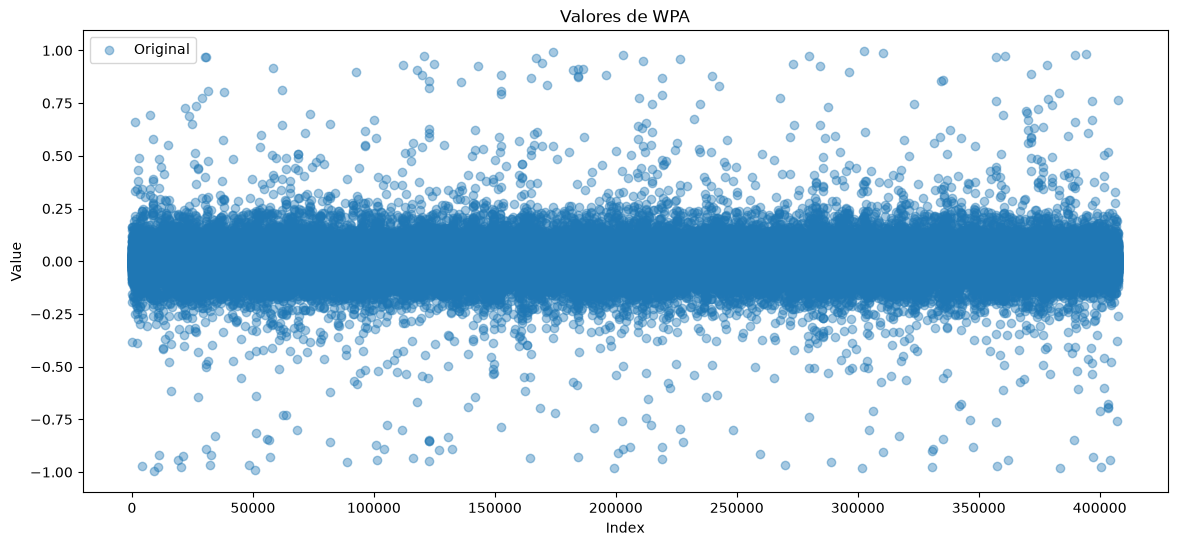

In [18]:
import matplotlib.pyplot as plt
import numpy as np

# Criar figura
plt.figure(figsize=(14,6))

# Scatter original
plt.scatter(df.index,df['WPA'],alpha=0.4,label='Original',)

plt.title('Valores de WPA')
plt.xlabel('Index')
plt.ylabel('Value')

plt.legend()
plt.show()

In [19]:
from sklearn.linear_model import LinearRegression  # importa modelo de regressão linear

def multiple_imputation_conditional_bootstrap(
    df,  # DataFrame original
    target='WPA',  # variável alvo a ser imputada
    predictors=('down', 'yrdline100', 'TimeSecs', 'ScoreDiff', 'GoalToGo'),  # variáveis preditoras
    M=10,  # número de datasets imputados a gerar
    random_state=42,  # semente aleatória para reprodutibilidade
    clip_range=None  # intervalo opcional para limitar valores imputados
):
    rng = np.random.default_rng(random_state)  # cria gerador de números aleatórios

    predictors = [p for p in predictors if p in df.columns]  # mantém apenas preditores existentes no df
    use_cols = predictors + [target]  # cria lista com preditores + alvo

    work = df[use_cols].copy()  # cria cópia de trabalho apenas com colunas relevantes

    # Garantir numérico
    for c in use_cols:  # percorre cada coluna usada
        work[c] = pd.to_numeric(work[c], errors='coerce')  # converte para numérico, NaN se falhar

    # Só imputar onde X_obs está disponível
    mask_X = work[predictors].notna().all(axis=1)  # linhas onde todos os preditores existem
    mask_obs = mask_X & work[target].notna()  # linhas com alvo observado
    mask_mis = mask_X & work[target].isna()  # linhas com alvo ausente

    X_obs = work.loc[mask_obs, predictors].to_numpy()  # matriz X observada
    y_obs = work.loc[mask_obs, target].to_numpy()  # vetor y observado
    X_mis = work.loc[mask_mis, predictors].to_numpy()  # matriz X com missing no alvo

    idx_obs = work.index[mask_obs].to_numpy()  # índices das linhas observadas
    idx_mis = work.index[mask_mis].to_numpy()  # índices das linhas missing

    datasets = []  # lista que armazenará os datasets imputados

    for m in range(M):  # repete processo M vezes

        # 1) Bootstrap das linhas observadas, introduz incerteza paramétrica
        boot_idx = rng.integers(0, len(y_obs), size=len(y_obs))  # sorteia índices com reposição
        Xb = X_obs[boot_idx]  # cria amostra bootstrap dos preditores
        yb = y_obs[boot_idx]  # cria amostra bootstrap do alvo

        model = LinearRegression()  # instancia modelo de regressão linear
        model.fit(Xb, yb)  # treina modelo com dados bootstrap

        # 2) Variância residual, introduz incerteza da imputação
        resid = yb - model.predict(Xb)  # calcula resíduos do modelo bootstrap

        # Amostragem dos resíduos, preserva forma empírica
        eps = rng.choice(resid, size=len(idx_mis), replace=True)  # sorteia resíduos aleatórios

        y_hat = model.predict(X_mis)  # calcula predição para linhas missing
        y_imp = y_hat + eps  # adiciona ruído para gerar imputação plausível

        if clip_range is not None:  # se intervalo foi definido
            lo, hi = clip_range  # define limite inferior e superior
            y_imp = np.clip(y_imp, lo, hi)  # limita valores ao intervalo

        df_m = df.copy()  # cria cópia completa do DataFrame original
        df_m.loc[idx_mis, target] = y_imp  # substitui missing pelos valores imputados
        df_m[f'{target}_imputed_flag'] = df[target].isna().astype(int)  # cria flag indicando imputação

        datasets.append(df_m)  # adiciona dataset imputado à lista

    return datasets  # retorna lista com M datasets imputados

ModuleNotFoundError: No module named 'sklearn'

In [ ]:
#Avaliar colunas completas e numéricas para usar de preditores
complete_numeric = [
    col for col in df.columns
    if df[col].isna().sum() == 0
    and pd.api.types.is_numeric_dtype(df[col])
]

complete_numeric

['GameID',
 'Drive',
 'qtr',
 'TimeUnder',
 'ydstogo',
 'ydsnet',
 'PlayAttempted',
 'Yards.Gained',
 'sp',
 'Touchdown',
 'Safety',
 'Onsidekick',
 'PassAttempt',
 'AirYards',
 'YardsAfterCatch',
 'QBHit',
 'InterceptionThrown',
 'RushAttempt',
 'Reception',
 'Fumble',
 'Sack',
 'Challenge.Replay',
 'Accepted.Penalty',
 'Penalty.Yards',
 'Timeout_Indicator',
 'posteam_timeouts_pre',
 'HomeTimeouts_Remaining_Pre',
 'AwayTimeouts_Remaining_Pre',
 'HomeTimeouts_Remaining_Post',
 'AwayTimeouts_Remaining_Post',
 'ExPoint_Prob',
 'TwoPoint_Prob',
 'Season']

### Análise das variáveis candidatas a preditodas

Todas as colunas listadas possuem **100% de completude**, mas nem todas são adequadas como preditoras. O critério principal é **evitar vazamento de informação (leakage)**, isto é, não usar variáveis que dependem do **resultado da jogada**, pois o WPA mede exatamente esse impacto.

A seguir está a classificação resumida.

---

### 1. Altamente recomendadas (estado do jogo pré-jogada)

Estas variáveis representam o **contexto antes da jogada** e são ideais para imputação:

**GameID**  
Identificador do jogo. Captura diferenças estruturais entre partidas.

**Drive**  
Número do drive. Representa o progresso temporal do jogo.

**qtr**  
Quarto do jogo. Forte relação com probabilidade de vitória.

**TimeUnder**  
Tempo restante no quarto. Excelente variável temporal.

**ydstogo**  
Jardas para first down. Variável situacional importante.

**posteam_timeouts_pre**  
Timeouts restantes do time ofensivo antes da jogada.

**HomeTimeouts_Remaining_Pre**  
Timeouts restantes do time da casa antes da jogada.

**AwayTimeouts_Remaining_Pre**  
Timeouts restantes do time visitante antes da jogada.

**Season**  
Ano da temporada. Captura variações estruturais entre temporadas.

---

### 2. Utilizáveis com cautela (contexto acumulado, mas ainda pré-resultado direto)

Podem ser usadas, mas dependem parcialmente do histórico do drive.

**ydsnet**  
Jardas acumuladas no drive.

**Timeout_Indicator**  
Indica ocorrência de timeout.

**Penalty.Yards**  
Jardas de penalidade. Pode refletir eventos da jogada.

---

### 3. Não recomendadas (resultado direto da jogada, leakage)

Estas variáveis descrevem o que aconteceu na jogada e não devem ser usadas.

**Yards.Gained**  
Resultado direto da jogada.

**Touchdown**  
Indica touchdown.

**Safety**  
Indica safety.

**PassAttempt**  
Indica tentativa de passe.

**RushAttempt**  
Indica tentativa de corrida.

**Reception**  
Indica recepção.

**AirYards**  
Jardas aéreas do passe.

**YardsAfterCatch**  
Jardas após recepção.

**QBHit**  
QB sofreu impacto.

**InterceptionThrown**  
Intercepção lançada.

**Fumble**  
Fumble ocorrido.

**Sack**  
QB sofreu sack.

**Onsidekick**  
Indica onside kick.

**Accepted.Penalty**  
Penalidade aceita.

**Challenge.Replay**  
Revisão de jogada.

**PlayAttempted**  
Indica se houve tentativa.

**sp**  
Indica pontuação.

---

### 4. Não recomendadas (informação pós-jogada, leakage temporal)

Estas variáveis usam informação posterior ao momento da jogada.

**HomeTimeouts_Remaining_Post**

**AwayTimeouts_Remaining_Post**

---

### 5. Não recomendadas (probabilidades derivadas do próprio modelo de vitória)

Estas variáveis são derivadas de modelos relacionados ao próprio conceito de WPA.

**ExPoint_Prob**

**TwoPoint_Prob**

Podem introduzir circularidade.

---

### Conjunto final recomendado

Para imputação estatisticamente correta de WPA:

- GameID
- Drive
- qtr
- TimeUnder
- ydstogo
- posteam_timeouts_pre
- HomeTimeouts_Remaining_Pre
- AwayTimeouts_Remaining_Pre
- Season
- ydsnet

In [ ]:
datasets_MI = multiple_imputation_conditional_bootstrap(

    df,  # DataFrame original que contém a coluna WPA com valores ausentes
    target='WPA',  # define que a variável a ser imputada é WPA
   predictors=('GameID','Drive','qtr','TimeUnder','ydstogo','posteam_timeouts_pre',
               'HomeTimeouts_Remaining_Pre','AwayTimeouts_Remaining_Pre','Season','ydsnet'),  
    # define as variáveis observadas usadas para estimar WPA, isso aproxima a distribuição condicional P(WPA | X_obs)
    
    M=10,  # define que serão gerados 10 datasets completos diferentes, cada dataset terá imputações diferentes para representar a incerteza

    random_state=42,  # fixa a semente aleatória para permitir reprodutibilidade, garante que o mesmo código produza os mesmos resultados

    clip_range=(-1, 1)  # limita os valores imputados ao intervalo válido de WPA
    # WPA é uma variação de probabilidade, então normalmente fica entre -1 e 1
)

### Análise dos resultados da imputação multipla

In [ ]:
print("Quantidade de datasets na coleção: ",len(datasets_MI))
print("Dimensão de cada dataset: ",datasets_MI[0].shape)

Quantidade de datasets na coleção:  10
Dimensão de cada dataset:  (407688, 103)


In [ ]:
# Empilha verticalmente os valores de WPA de cada dataset imputado
stack = np.vstack([d['WPA'].to_numpy() for d in datasets_MI])
# Resultado: array NumPy de dimensão (M, N), onde: M = número de imputações (10) e N = número de linhas do dataset (407688)

df['WPA_MI_mean'] = stack.mean(axis=0) # Calcula a média das imputações para cada linha
df['WPA_MI_std'] = stack.std(axis=0, ddof=1) # Calcula o desvio padrão entre imputações para cada linha

## O que foi feito!
Após executar a imputação múltipla com $M = 10$, cada observação $i$ que originalmente tinha valor ausente passou a ter **10 valores plausíveis diferentes**:

$
WPA_i^{(1)},\;
WPA_i^{(2)},\;
\dots,\;
WPA_i^{(10)}
$

Cada um desses valores representa uma amostra da distribuição condicional estimada:

$
P(WPA_i \mid X_{obs})
$

### Média das imputações

A estimativa pontual média para cada observação é dada por:

$
\bar{WPA}_i
=
\frac{1}{10}
\sum_{m=1}^{10}
WPA_i^{(m)}
$

Essa média representa o **valor imputado esperado** para aquela observação.


### Desvio padrão das imputações

A incerteza associada à imputação é medida pelo desvio padrão:

$
SD_i
=
\sqrt{
\frac{1}{9}
\sum_{m=1}^{10}
\left(
WPA_i^{(m)}
-
\bar{WPA}_i
\right)^2
}
$

Esse valor indica **quanto as imputações variam entre si**.

- Desvio padrão baixo, alta confiança na imputação  
- Desvio padrão alto, maior incerteza  

---

### Interpretação prática no DataFrame

Após o processo, o DataFrame contém três versões da variável:

- **WPA**, valor original, podendo conter missing  
- **WPA_MI_mean**, média das imputações múltiplas  
- **WPA_MI_std**, incerteza associada à imputação  

### Exemplo

| index | WPA original | WPA_MI_mean | WPA_MI_std |
|------|--------------|-------------|------------|
| 10   | NaN          | -0.023      | 0.011      |
| 11   | NaN          | 0.045       | 0.032      |
| 12   | 0.012        | 0.012       | 0.000      |

## Interpretação do exemplo

**Index 10 e 11**

O valor original era ausente.

A imputação múltipla estimou um valor médio plausível e quantificou a incerteza.

**Index 12**

O valor original existia.

Portanto, todas as imputações coincidem com o valor original, resultando em:

$
SD = 0
$

---

## Conclusão conceitual

A imputação múltipla não produz apenas um único valor imputado, mas sim:

- uma **estimativa pontual**, $\bar{WPA}_i$
- uma **medida de incerteza**, $SD_i$

Isso permite preservar a variabilidade dos dados e representar corretamente a incerteza associada aos valores ausentes.

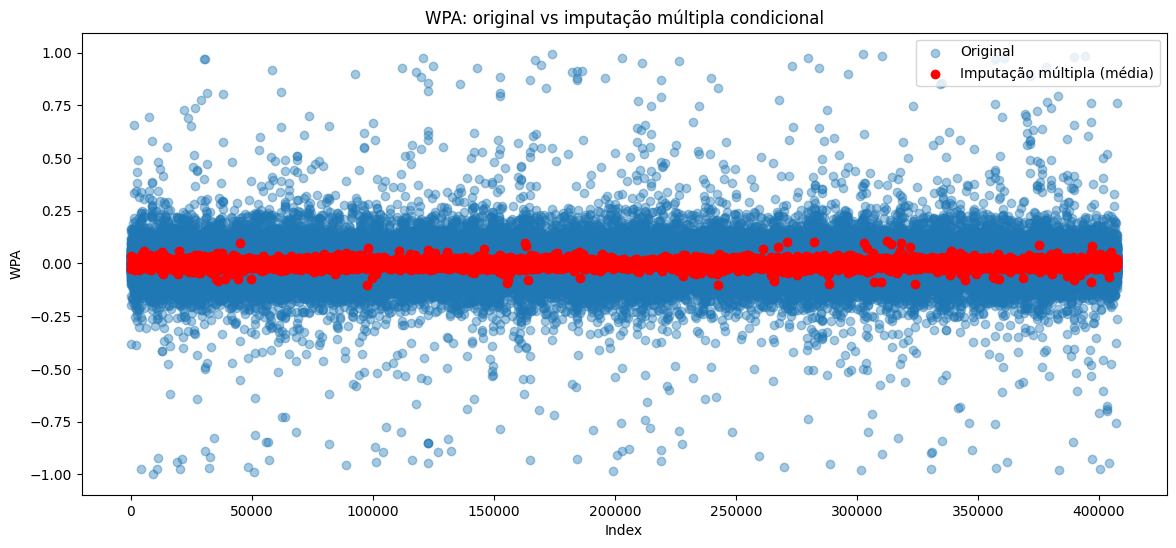

In [ ]:
missing_mask = df['WPA'].isna() # cria uma máscara booleana:
# True para linhas onde WPA é NaN
# False para linhas onde WPA tem valor observado

plt.figure(figsize=(14,6))  

# valores originais
plt.scatter(
    df.index,      # eixo x: índice das observações
    df['WPA'],     # eixo y: valores originais de WPA (inclui NaN, que não serão plotados)
    alpha=0.4,     # transparência dos pontos, melhora visualização em datasets grandes
    label='Original'  # nome da série para a legenda
)

# valores imputados (média MI)
plt.scatter(
    df.index[missing_mask],  # eixo x: apenas índices onde WPA era missing originalmente
    df.loc[missing_mask, 'WPA_MI_mean'],  # eixo y: valores imputados médios nesses pontos missing
    color='red',  # define cor vermelha para destacar imputações
    label='Imputação múltipla (média)',  # nome da série para legenda
    zorder=3  # define prioridade visual, garantindo que pontos vermelhos fiquem na frente
)

plt.title('WPA: original vs imputação múltipla condicional')  
plt.xlabel('Index')  
plt.ylabel('WPA')  
plt.legend(loc='upper right')  
plt.show()  

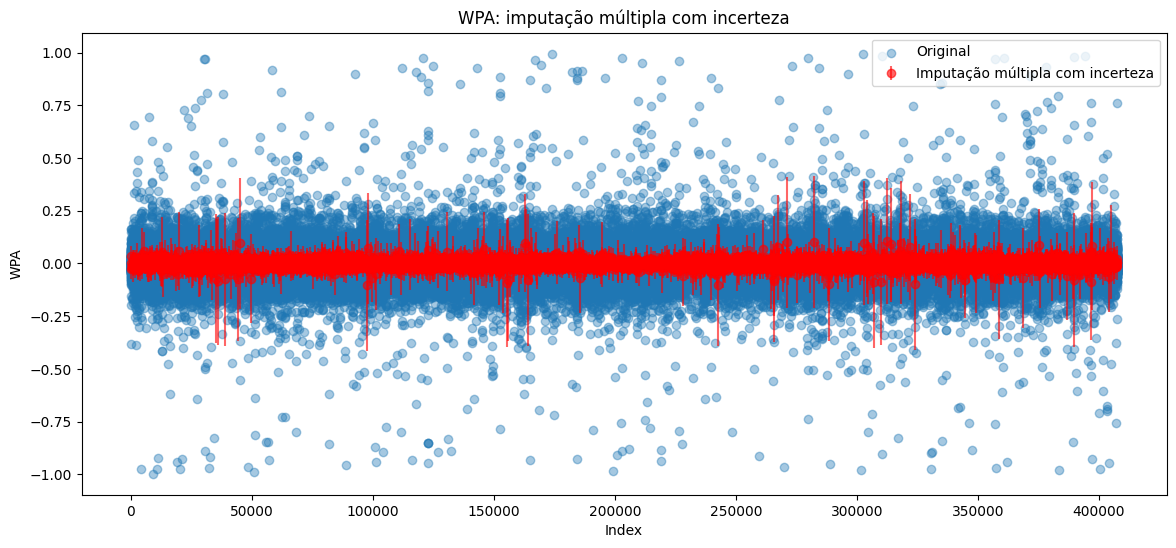

In [ ]:
stack = np.vstack([d['WPA'].to_numpy() for d in datasets_MI])

mean = stack.mean(axis=0)
std = stack.std(axis=0)

plt.figure(figsize=(14,6))

plt.scatter(df.index, df['WPA'], alpha=0.4, label='Original')

plt.errorbar(
    df.index[missing_mask],                  # eixo x: apenas observações que tinham missing
    df.loc[missing_mask, 'WPA_MI_mean'],    # eixo y: média imputada
    yerr=df.loc[missing_mask, 'WPA_MI_std'],# tamanho da barra de erro = incerteza da imputação
    fmt='o',                                # formato do marcador
    color='red',                            # cor do ponto
    ecolor='red',                           # cor da barra de erro
    alpha=0.6,                              # transparência
    zorder=3,                               # prioridade visual
    label='Imputação múltipla com incerteza' # legenda correta
)

plt.title('WPA: imputação múltipla com incerteza')
plt.xlabel('Index')
plt.ylabel('WPA')
plt.legend(loc='upper right')
plt.show()

### Resultados no Dataframe

In [ ]:
df[['WPA', 'WPA_MI_mean', 'WPA_MI_std']].isna().sum()

WPA            5541
WPA_MI_mean       0
WPA_MI_std        0
dtype: int64

## Continuando:
### Limiar de corte
Após analisar cada coluna, se supostamente, decidir que alcumas colunas são irrelevantes para a análise, remova do DATASET

In [ ]:
# Abordagem hipotética
cols_remove = list(missing_10_20.tolist()+ missing_20_30.tolist()+ missing_30_50.tolist()+ missing_50.tolist())
cols_remove

['down',
 'Tackler1',
 'ExPointResult',
 'TwoPointConv',
 'DefTwoPoint',
 'PuntResult',
 'Passer',
 'Passer_ID',
 'PassOutcome',
 'PassLength',
 'PassLocation',
 'Interceptor',
 'Rusher',
 'Rusher_ID',
 'RunLocation',
 'RunGap',
 'Receiver',
 'Receiver_ID',
 'ReturnResult',
 'Returner',
 'BlockingPlayer',
 'Tackler2',
 'FieldGoalResult',
 'FieldGoalDistance',
 'RecFumbTeam',
 'RecFumbPlayer',
 'ChalReplayResult',
 'PenalizedTeam',
 'PenaltyType',
 'PenalizedPlayer',
 'Timeout_Team',
 'airEPA',
 'yacEPA',
 'airWPA',
 'yacWPA']

In [ ]:
df.drop(columns=cols_remove, inplace=True)

In [ ]:
missing = df.isna().sum().sort_values(ascending=False)
missing

FirstDown                      28811
PosTeamScore                   26904
DefTeamScore                   26904
AbsScoreDiff                   26904
Away_WP_post                   26587
Home_WP_post                   26587
Win_Prob                       25009
DefensiveTeam                  24992
posteam                        24992
ScoreDiff                      24988
Home_WP_pre                    24954
Away_WP_pre                    24954
WPA                             5541
GoalToGo                         840
yrdln                            840
yrdline100                       840
SideofField                      528
PlayTimeDiff                     444
EPA                              369
time                             224
TimeSecs                         224
Opp_Touchdown_Prob               176
Touchdown_Prob                   176
ExpPts                           176
Safety_Prob                      176
Field_Goal_Prob                  176
Opp_Safety_Prob                  176
O

# Exercício
Tratar o restante dos dados e fazer imputação para os valores ausentes